# GA4 Ecommerce Session Funnel Analysis

## Summary

- **3.49%** of product-view sessions completed the ordered purchase funnel (348 / 9,965).
- The largest adjacent-stage loss was view → cart: **8,158 sessions / 81.87%**.
- Tablet conversion was 5.61%, based on only 12 purchases and 214 views; do not treat the device ranking as a stable or causal advantage.

## Context & Methods

Source: Google's obfuscated GA4 ecommerce sample, 2020-11-01 through 2021-01-31.
The checked-in CSV is a 10,000-row snapshot; extraction logic is in `sql/02_export_session_funnel_sample.sql`.
One row represents a pseudonymous user-session. Eligible sessions contain at least one of the six selected funnel events; this is **not a sample of all website sessions**.
The SQL filters events before aggregation, so `session_date` is the earliest selected event date in that session.
Stages must occur in the same session with **strictly increasing timestamps**: view item → add to cart → begin checkout → purchase.
Rates use sessions reaching the starting stage as the denominator. Completed purchases outside this sequence are excluded.

### Key assumptions and limitations

- The same user may appear in multiple sessions; sessions are not unique customers.
- The public data is obfuscated and historical. Tracking completeness and representativeness are not established.
- Source/medium are first-user acquisition fields, not current-session acquisition fields.
- SQL uses ANY_VALUE for descriptive session dimensions; event-level dimension conflicts were not independently audited.
- MySQL reconciliation uses the saved export, not a fresh database connection. This is descriptive analysis, not causal or significance testing.

## Setup

Install `requirements.txt`, select that Python environment in Jupyter, and run all cells.
Run from the project root or `notebooks/`; paths below resolve the project root automatically.
The run overwrites derived CSVs in `results/` and PNGs in `figures/`; input CSV and MySQL TSV remain unchanged.
This public notebook contains the presentation analysis; private learning records are excluded.


In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data/ga4_session_funnel_sample.csv").is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the GA4 project root or notebooks directory")
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)
print("pandas:", pd.__version__)


pandas: 3.0.6


## Data

### Load identifiers as text

In [2]:
df = pd.read_csv(
    DATA_DIR / "ga4_session_funnel_sample.csv",
    dtype={
        "user_pseudo_id": "string",
        "ga_session_id": "string"
    }
)

df.head()

,user_pseudo_id,ga_session_id,session_date,device_category,country,first_user_source,first_user_medium,funnel_event_count,view_item_event_count,add_to_cart_event_count,...,first_add_to_cart_utc,first_begin_checkout_utc,first_purchase_utc,add_to_cart_after_view_utc,begin_checkout_after_cart_utc,purchase_after_checkout_utc,has_view_item,has_add_to_cart_after_view,has_checkout_after_cart,has_purchase_after_checkout
0,65889442.7744827202,5763727091,2020-11-25,mobile,China,(direct),(none),12,6,6,...,2020-11-25 21:57:44.206104 UTC,NaN,NaN,2020-11-25 21:57:44.206104 UTC,NaN,NaN,True,True,False,False
1,7224680559.5002681278,4103354871,2020-12-08,mobile,Israel,google,organic,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,False,False,False
2,7564275.7556255677,8755580119,2020-11-20,desktop,Taiwan,<Other>,referral,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,False,False,False
3,4396894.6112781516,5928199009,2020-12-17,desktop,Serbia,google,organic,35,22,2,...,2020-12-17 16:45:00.353102 UTC,2020-12-17 16:56:13.450644 UTC,2020-12-17 16:59:51.861994 UTC,2020-12-17 16:45:00.353102 UTC,2020-12-17 16:56:13.450644 UTC,2020-12-17 16:59:51.861994 UTC,True,True,True,True
4,41179206.8501474127,310192105,2020-12-07,mobile,India,<Other>,organic,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,True,False,False,False


In [3]:
df.shape

(10000, 25)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   user_pseudo_id                 10000 non-null  string
 1   ga_session_id                  10000 non-null  string
 2   session_date                   10000 non-null  str   
 3   device_category                10000 non-null  str   
 4   country                        10000 non-null  str   
 5   first_user_source              10000 non-null  str   
 6   first_user_medium              10000 non-null  str   
 7   funnel_event_count             10000 non-null  int64 
 8   view_item_event_count          10000 non-null  int64 
 9   add_to_cart_event_count        10000 non-null  int64 
 10  begin_checkout_event_count     10000 non-null  int64 
 11  add_shipping_info_event_count  10000 non-null  int64 
 12  add_payment_info_event_count   10000 non-null  int64 
 13  purchase_even

In [5]:
df.isna().sum()

user_pseudo_id                      0
ga_session_id                       0
session_date                        0
device_category                     0
country                             0
first_user_source                   0
first_user_medium                   0
funnel_event_count                  0
view_item_event_count               0
add_to_cart_event_count             0
begin_checkout_event_count          0
add_shipping_info_event_count       0
add_payment_info_event_count        0
purchase_event_count                0
first_view_item_utc                35
first_add_to_cart_utc            8089
first_begin_checkout_utc         8623
first_purchase_utc               9408
add_to_cart_after_view_utc       8193
begin_checkout_after_cart_utc    9356
purchase_after_checkout_utc      9652
has_view_item                       0
has_add_to_cart_after_view          0
has_checkout_after_cart             0
has_purchase_after_checkout         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.duplicated(
    subset=["user_pseudo_id", "ga_session_id"]
).sum()

np.int64(0)

In [8]:
df["session_date"].agg(["min", "max", "nunique"])

min        2020-11-01
max        2021-01-31
nunique            92
Name: session_date, dtype: object

In [9]:
df["device_category"].value_counts(dropna=False)

device_category
desktop    5838
mobile     3947
tablet      215
Name: count, dtype: int64

In [10]:
funnel_columns = [
    "has_view_item",
    "has_add_to_cart_after_view",
    "has_checkout_after_cart",
    "has_purchase_after_checkout"
]

df[funnel_columns].sum()

has_view_item                  9965
has_add_to_cart_after_view     1807
has_checkout_after_cart         644
has_purchase_after_checkout     348
dtype: int64

In [11]:
assert df.shape == (10000, 25), "Snapshot dimensions differ from the baseline"

assert df[
    ["user_pseudo_id", "ga_session_id"]
].isna().sum().sum() == 0, "Missing session key"

assert df.duplicated(
    subset=["user_pseudo_id", "ga_session_id"]
).sum() == 0, "Duplicate user-session key"

print("Basic checks passed")

Basic checks passed


## Initial data checks

- The input has 10,000 rows and 25 columns; each row is one pseudonymous user-session.
- The composite session key has no missing values or duplicates; no fully duplicated rows were found.
- `session_date` covers 92 dates, from 2020-11-01 through 2021-01-31.
- Device-category frequencies were inspected.
- Ordered stage counts are 9,965 views, 1,807 carts, 644 checkouts and 348 purchases.
- Missing timestamps are retained and checked against event counts and stage flags below.
- At this point, dates and timestamps are still strings; parsing and validity checks follow.

### Parse dates and UTC timestamps

In [12]:
df["session_date_original"] = df["session_date"].copy()

In [13]:
df["session_date"] = pd.to_datetime(
    df["session_date_original"],
    format="%Y-%m-%d",
    errors="coerce"
)

In [14]:
date_invalid = (
    df["session_date_original"].notna()
    & df["session_date"].isna()
)

print("Date dtype:", df["session_date"].dtype)
print("Date parse failures:", date_invalid.sum())

Date dtype: datetime64[us]
Date parse failures: 0


In [15]:
df["first_view_item_utc_original"] = df["first_view_item_utc"].copy()

In [16]:
df["first_view_item_utc"] = pd.to_datetime(
    df["first_view_item_utc_original"],
    format="mixed",
    errors="coerce",
    utc=True
)

In [17]:
view_time_invalid = (
    df["first_view_item_utc_original"].notna()
    & df["first_view_item_utc"].isna()
)

print("Timestamp dtype:", df["first_view_item_utc"].dtype)
print("Parse failures:", view_time_invalid.sum())
print("Missing after parsing:", df["first_view_item_utc"].isna().sum())

Timestamp dtype: datetime64[us, UTC]
Parse failures: 0
Missing after parsing: 35


### Check flags, counts and timestamps

In [18]:
view_flag_mismatch = (
    df["first_view_item_utc"].notna()
    != df["has_view_item"]
)

view_count_mismatch = (
    (df["view_item_event_count"] > 0)
    != df["has_view_item"]
)

print("Timestamp/flag mismatches:", view_flag_mismatch.sum())
print("Count/flag mismatches:", view_count_mismatch.sum())

Timestamp/flag mismatches: 0
Count/flag mismatches: 0


In [19]:
time_columns = [
    "first_add_to_cart_utc",
    "first_begin_checkout_utc",
    "first_purchase_utc",
    "add_to_cart_after_view_utc",
    "begin_checkout_after_cart_utc",
    "purchase_after_checkout_utc"
]

In [20]:
time_original = df[time_columns].copy()

In [21]:
for column in time_columns:
    df[column] = pd.to_datetime(
        time_original[column],
        format="mixed",
        errors="coerce",
        utc=True
    )

    invalid = (
        time_original[column].notna()
        & df[column].isna()
    )

    print(column, "Parse failures:", invalid.sum())

first_add_to_cart_utc Parse failures: 0
first_begin_checkout_utc Parse failures: 0
first_purchase_utc Parse failures: 0
add_to_cart_after_view_utc Parse failures: 0
begin_checkout_after_cart_utc Parse failures: 0
purchase_after_checkout_utc Parse failures: 0


In [22]:
stage_pairs = [
    ("has_add_to_cart_after_view", "add_to_cart_after_view_utc"),
    ("has_checkout_after_cart", "begin_checkout_after_cart_utc"),
    ("has_purchase_after_checkout", "purchase_after_checkout_utc")
]

for flag, timestamp in stage_pairs:
    mismatch = df[flag] != df[timestamp].notna()

    print(flag, "Mismatches:", mismatch.sum())

has_add_to_cart_after_view Mismatches: 0
has_checkout_after_cart Mismatches: 0
has_purchase_after_checkout Mismatches: 0


In [23]:
time_pairs = [
    ("first_view_item_utc", "add_to_cart_after_view_utc"),
    ("add_to_cart_after_view_utc", "begin_checkout_after_cart_utc"),
    ("begin_checkout_after_cart_utc", "purchase_after_checkout_utc")
]

for earlier, later in time_pairs:
    invalid_order = (
        df[later].notna()
        & (
            df[earlier].isna()
            | (df[later] < df[earlier])
        )
    )

    print(later, "Stage-order violations:", invalid_order.sum())

add_to_cart_after_view_utc Stage-order violations: 0
begin_checkout_after_cart_utc Stage-order violations: 0
purchase_after_checkout_utc Stage-order violations: 0


### Check event-count validity

In [24]:
count_columns = [
    "funnel_event_count",
    "view_item_event_count",
    "add_to_cart_event_count",
    "begin_checkout_event_count",
    "add_shipping_info_event_count",
    "add_payment_info_event_count",
    "purchase_event_count"
]

In [25]:
for column in count_columns:
    missing = df[column].isna().sum()
    negative = (df[column] < 0).sum()

    fractional = (
        df[column].notna()
        & (df[column] % 1 != 0)
    ).sum()

    print(
        column,
        "Missing:", missing,
        "Negative:", negative,
        "Non-integer:", fractional
    )

funnel_event_count Missing: 0 Negative: 0 Non-integer: 0
view_item_event_count Missing: 0 Negative: 0 Non-integer: 0
add_to_cart_event_count Missing: 0 Negative: 0 Non-integer: 0
begin_checkout_event_count Missing: 0 Negative: 0 Non-integer: 0
add_shipping_info_event_count Missing: 0 Negative: 0 Non-integer: 0
add_payment_info_event_count Missing: 0 Negative: 0 Non-integer: 0
purchase_event_count Missing: 0 Negative: 0 Non-integer: 0


In [26]:
event_pairs = [
    ("add_to_cart_event_count", "first_add_to_cart_utc"),
    ("begin_checkout_event_count", "first_begin_checkout_utc"),
    ("purchase_event_count", "first_purchase_utc")
]

for count, timestamp in event_pairs:
    mismatch = (
        (df[count] > 0)
        != df[timestamp].notna()
    )

    print(count, "Count/timestamp mismatches:", mismatch.sum())

add_to_cart_event_count Count/timestamp mismatches: 0
begin_checkout_event_count Count/timestamp mismatches: 0
purchase_event_count Count/timestamp mismatches: 0


In [27]:
date_out_of_range = (
    (df["session_date"] < pd.Timestamp("2020-11-01"))
    | (df["session_date"] > pd.Timestamp("2021-01-31"))
)

print("Missing dates:", df["session_date"].isna().sum())
print("Dates outside the sample period:", date_out_of_range.sum())

Missing dates: 0
Dates outside the sample period: 0


## Type conversion and consistency

- `session_date` was parsed successfully, with no missing dates or dates outside the sample period.
- Seven event timestamp columns were parsed to UTC; all parse-failure counts were zero.
- The 35 originally missing first-view timestamps were preserved; parsing introduced no additional missing values.
- View counts, timestamps and flags were checked for consistency.
- Ordered stage flags match their timestamps. No missing prerequisites or reversed stage times were found.
- Event counts contain no missing, negative or fractional values.
- Cart, checkout and purchase counts match the presence of their first-event timestamps.
- Timestamps were not arbitrarily imputed, and sessions were not deleted solely because an event time was absent.
- These checks establish consistency under the tested rules, not complete source-event tracking.

### Reconcile total event counts

In [28]:
event_columns = [
    "view_item_event_count",
    "add_to_cart_event_count",
    "begin_checkout_event_count",
    "add_shipping_info_event_count",
    "add_payment_info_event_count",
    "purchase_event_count",
]

calculated_total = df[event_columns].sum(axis=1)

total_mismatch = df["funnel_event_count"] != calculated_total

print("Sessions with total/component count mismatches:", total_mismatch.sum())

Sessions with total/component count mismatches: 0


## Data-quality conclusions

### Snapshot and keys
- The original input has 10,000 rows and 25 columns, with one row per user-session.
- Full-row duplicates and composite session-key checks passed.

### Dates and timestamps
- Dates are complete and range from 2020-11-01 to 2021-01-31.
- Date parsing and all seven UTC timestamp conversions produced zero failures.
- The 35 missing first-view timestamps were unchanged by parsing. Their view-event counts are zero; these records were retained without imputation.

### Event counts and consistency
- All seven count columns contain nonnegative integers and no missing values.
- Each session's total equals the sum of its six target-event counts.
- View, cart, checkout and purchase counts match their first-event timestamps.
- Stage flags and timestamps are consistent; ordered-stage checks passed.

### Limitations
- Passing internal checks does not establish complete event tracking.
- Missing timestamps must be interpreted alongside event occurrence and order, rather than uniformly imputed or deleted.
- First-user source/medium describe initial acquisition, not the current session's source.
- The snapshot includes only sessions containing a target event, and does not represent all website sessions.

### Validate strict stage order

In [29]:
time_pairs = [
    ("first_view_item_utc", "add_to_cart_after_view_utc"),
    ("add_to_cart_after_view_utc", "begin_checkout_after_cart_utc"),
    ("begin_checkout_after_cart_utc", "purchase_after_checkout_utc"),
]

for earlier, later in time_pairs:
    invalid_order = (
        df[later].notna()
        & (
            df[earlier].isna()
            | (df[later] <= df[earlier])
        )
    )

    print(later, "Strict stage-order violations:", invalid_order.sum())

add_to_cart_after_view_utc Strict stage-order violations: 0
begin_checkout_after_cart_utc Strict stage-order violations: 0
purchase_after_checkout_utc Strict stage-order violations: 0


## Results

### Device funnel and saved MySQL reconciliation

In [30]:
device_funnel_python = df.groupby("device_category").agg(
    total_sessions=("ga_session_id", "size"),
    view_sessions=("has_view_item", "sum"),
    cart_sessions=("has_add_to_cart_after_view", "sum"),
    checkout_sessions=("has_checkout_after_cart", "sum"),
    purchase_sessions=("has_purchase_after_checkout", "sum")
)

device_funnel_python

,total_sessions,view_sessions,cart_sessions,checkout_sessions,purchase_sessions
device_category,,,,,
desktop,5838,5824,1055,364,199
mobile,3947,3927,721,267,137
tablet,215,214,31,13,12


In [31]:
device_funnel_python["view_to_purchase_pct"] = (
    device_funnel_python["purchase_sessions"]
    / device_funnel_python["view_sessions"].replace(0, float("nan"))
    * 100
).round(2)

device_funnel_python[
    ["view_sessions", "purchase_sessions", "view_to_purchase_pct"]
]

,view_sessions,purchase_sessions,view_to_purchase_pct
device_category,,,
desktop,5824,199,3.42
mobile,3927,137,3.49
tablet,214,12,5.61


In [32]:
device_funnel_python["view_to_cart_pct"] = (
    device_funnel_python["cart_sessions"]
    / device_funnel_python["view_sessions"].replace(0, float("nan"))
    * 100
).round(2)

device_funnel_python["cart_to_checkout_pct"] = (
    device_funnel_python["checkout_sessions"]
    / device_funnel_python["cart_sessions"].replace(0, float("nan"))
    * 100
).round(2)

device_funnel_python["checkout_to_purchase_pct"] = (
    device_funnel_python["purchase_sessions"]
    / device_funnel_python["checkout_sessions"].replace(0, float("nan"))
    * 100
).round(2)

device_funnel_python

,total_sessions,view_sessions,cart_sessions,checkout_sessions,purchase_sessions,view_to_purchase_pct,view_to_cart_pct,cart_to_checkout_pct,checkout_to_purchase_pct
device_category,,,,,,,,,
desktop,5838,5824,1055,364,199,3.42,18.11,34.50,54.67
mobile,3947,3927,721,267,137,3.49,18.36,37.03,51.31
tablet,215,214,31,13,12,5.61,14.49,41.94,92.31


In [33]:
device_funnel_python.to_csv(
    RESULTS_DIR / "ga4_device_funnel_python.csv",
    index=True
)

In [34]:
mysql_export = pd.read_csv(
    RESULTS_DIR / "ga4_device_funnel_mysql.tsv",
    sep="\t",
    quotechar="'"
)

mysql_export = mysql_export.rename(
    columns={"# device_category": "device_category"}
)

print(mysql_export.shape)
mysql_export

(3, 10)


,device_category,total_sessions,view_sessions,cart_sessions,checkout_sessions,purchase_sessions,view_to_purchase_pct,view_to_cart_pct,cart_to_checkout_pct,checkout_to_purchase_pct
0,desktop,5838,5824,1055,364,199,3.42,18.11,34.50,54.67
1,mobile,3947,3927,721,267,137,3.49,18.36,37.03,51.31
2,tablet,215,214,31,13,12,5.61,14.49,41.94,92.31


In [35]:
mysql_export.to_csv(
    RESULTS_DIR / "ga4_device_funnel_mysql.csv",
    index=False
)

python_result = pd.read_csv(
    RESULTS_DIR / "ga4_device_funnel_python.csv",
    index_col="device_category"
)

mysql_result = mysql_export.set_index("device_category")

python_result = python_result.sort_index().sort_index(axis=1)
mysql_result = mysql_result.sort_index().sort_index(axis=1)

assert python_result.index.is_unique, "Duplicate device in Python results"
assert mysql_result.index.is_unique, "Duplicate device in MySQL results"

pd.testing.assert_frame_equal(
    python_result,
    mysql_result,
    check_dtype=False,
    check_exact=True
)

print("Reconciliation passed: devices, columns and all aggregate metrics match")

Reconciliation passed: devices, columns and all aggregate metrics match


## Python and saved MySQL reconciliation

- Total session counts and all four ordered stage counts match for all three devices.
- View-to-purchase, view-to-cart, cart-to-checkout and checkout-to-purchase percentages match.
- Automated comparisons cover device keys, column names and every aggregate metric, with rates rounded to two decimal places.
- This compares saved device aggregates; it does not establish full row-by-row equality with the original MySQL table.

### Overall stage conversion

In [36]:
overall_counts = df[
    [
        "has_view_item",
        "has_add_to_cart_after_view",
        "has_checkout_after_cart",
        "has_purchase_after_checkout"
    ]
].sum()

overall_counts

has_view_item                  9965
has_add_to_cart_after_view     1807
has_checkout_after_cart         644
has_purchase_after_checkout     348
dtype: int64

In [37]:
overall_view_to_cart_pct = (
    overall_counts["has_add_to_cart_after_view"]
    / overall_counts["has_view_item"]
    * 100
).round(2)

overall_view_to_cart_pct

np.float64(18.13)

In [38]:
overall_cart_to_checkout_pct = (
    overall_counts["has_checkout_after_cart"]
    / overall_counts["has_add_to_cart_after_view"]
    * 100
).round(2)

overall_cart_to_checkout_pct

np.float64(35.64)

In [39]:
overall_checkout_to_purchase_pct = (
    overall_counts["has_purchase_after_checkout"]
    / overall_counts["has_checkout_after_cart"]
    * 100
).round(2)

overall_checkout_to_purchase_pct

np.float64(54.04)

In [40]:
overall_view_to_purchase_pct = (
    overall_counts["has_purchase_after_checkout"]
    / overall_counts["has_view_item"]
    * 100
).round(2)

overall_view_to_purchase_pct

np.float64(3.49)

In [41]:
overall_funnel = pd.DataFrame({
    "stage": ["View item", "Add to cart", "Begin checkout", "Purchase"],
    "sessions": [
        overall_counts["has_view_item"],
        overall_counts["has_add_to_cart_after_view"],
        overall_counts["has_checkout_after_cart"],
        overall_counts["has_purchase_after_checkout"]
    ],
    "conversion_from_previous_pct": [
        float("nan"),
        overall_view_to_cart_pct,
        overall_cart_to_checkout_pct,
        overall_checkout_to_purchase_pct
    ]
})

overall_funnel

,stage,sessions,conversion_from_previous_pct
0,View item,9965,NaN
1,Add to cart,1807,18.13
2,Begin checkout,644,35.64
3,Purchase,348,54.04


### Overall funnel chart

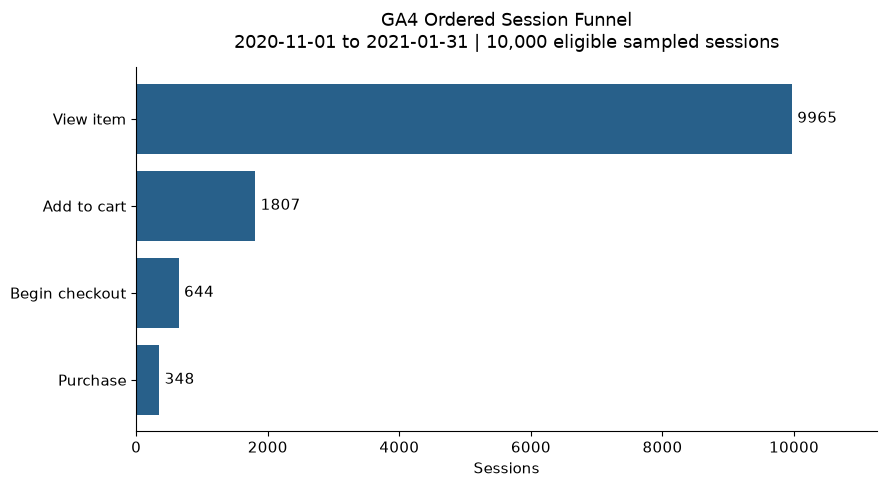

In [42]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    overall_funnel["stage"],
    overall_funnel["sessions"],
    color="#28608A"
)

ax.bar_label(ax.containers[0], padding=4)
ax.invert_yaxis()
ax.set_yticks(range(4))
ax.set_yticklabels(["View item", "Add to cart", "Begin checkout", "Purchase"])
ax.set_xlabel("Sessions")
ax.set_title("GA4 Ordered Session Funnel\n2020-11-01 to 2021-01-31 | 10,000 eligible sampled sessions", pad=14)
ax.margins(x=0.13)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "ga4_overall_funnel.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In this snapshot's ordered funnel, view sessions fell from 9,965 to 1,807 cart sessions: a loss of 8,158 sessions, or 81.87%. This is the largest adjacent-stage decline by both count and percentage. These results alone do not establish why sessions dropped off.

### Device conversion chart

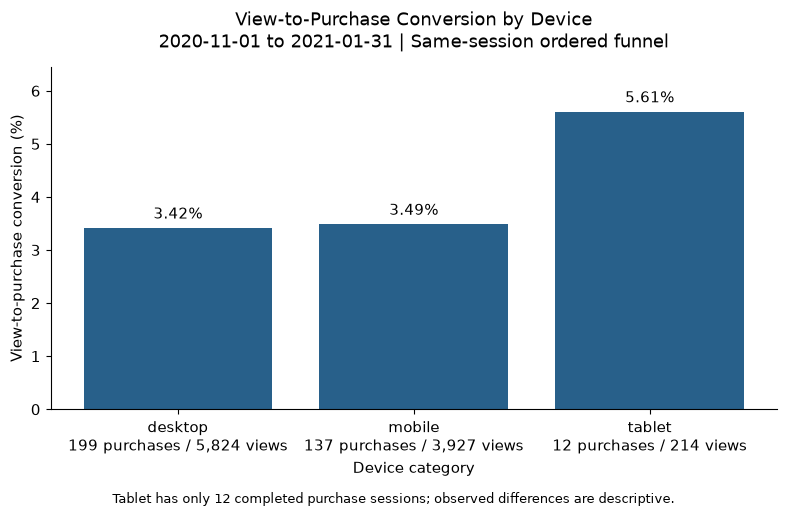

In [43]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    device_funnel_python.index,
    device_funnel_python["view_to_purchase_pct"],
    color="#28608A"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_xlabel("Device category")
ax.set_ylabel("View-to-purchase conversion (%)")
ax.set_title("View-to-Purchase Conversion by Device\n2020-11-01 to 2021-01-31 | Same-session ordered funnel", pad=14)
ax.set_xticks(range(len(device_funnel_python)))
ax.set_xticklabels([f"{device}\n{int(row.purchase_sessions):,} purchases / {int(row.view_sessions):,} views" for device, row in device_funnel_python.iterrows()])
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.02, "Tablet has only 12 completed purchase sessions; observed differences are descriptive.", ha="center", fontsize=9)
ax.margins(y=0.15)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "ga4_device_conversion.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

Tablet has the highest observed view-to-purchase rate at 5.61%, compared with 3.42% for desktop and 3.49% for mobile. However, tablet has only 12 funnel-completing purchase sessions. This small sample does not establish a stable conversion advantage or a causal device effect.

In [44]:
device_funnel_python[
    ["view_sessions", "purchase_sessions", "view_to_purchase_pct"]
]

,view_sessions,purchase_sessions,view_to_purchase_pct
device_category,,,
desktop,5824,199,3.42
mobile,3927,137,3.49
tablet,214,12,5.61


### Export overall results

In [45]:
overall_funnel.to_csv(
    RESULTS_DIR / "ga4_overall_funnel_python.csv",
    index=False
)

## Takeaways & Business Summary

### Scope and metric definitions

This analysis uses a 10,000-session sample covering November 1, 2020,
to January 31, 2021, from Google's obfuscated GA4 ecommerce dataset.

The sample includes sessions with at least one of the six selected funnel events; it does not represent all website sessions.

The funnel follows this sequence within the same session:
view item → add to cart → begin checkout → purchase.

Conversion rates use sessions reaching the starting stage as the
denominator. These metrics describe sessions, not unique customers.

### Key findings

1. Overall view-to-purchase conversion was 3.49%:
   348 of 9,965 sessions with a product view completed the ordered funnel.

2. The largest adjacent-stage drop occurred between viewing and adding
   to cart. Session counts fell from 9,965 to 1,807, a loss of 8,158
   sessions and a stage drop-off rate of 81.87%.

3. View-to-purchase conversion was 3.42% for desktop, 3.49% for mobile,
   and 5.61% for tablet. Tablet had only 214 product-view sessions and
   12 funnel-completing purchase sessions, so its higher observed rate
   should be interpreted cautiously.

### Recommended next steps

1. Investigate the view-to-cart stage first. Validate event tracking,
   then examine product availability, pricing, traffic mix, and
   add-to-cart interactions. These are hypotheses to investigate,
   not established causes of drop-off.

2. Before prioritizing a device-specific change, examine conversion
   across time periods and comparable traffic/product segments.
   Validate any proposed improvement through a properly designed
   experiment rather than treating observed device differences
   as causal effects.

### Limitations

- The data is an obfuscated historical sample; findings may not
  generalize to current traffic or the full business.
- Missing or incomplete event tracking can affect funnel counts.
- The same user may contribute multiple sessions.
- Purchases outside the defined same-session sequence are not counted
  as completed funnel purchases.
- This is descriptive analysis. No causal effect, statistical
  significance, or realized business improvement is established.

In [46]:
overall_kpis = pd.DataFrame({
    "total_sessions": [len(df)],
    "view_sessions": [overall_counts["has_view_item"]],
    "purchase_sessions": [
        overall_counts["has_purchase_after_checkout"]
    ],
    "view_to_purchase_pct": [overall_view_to_purchase_pct]
})

overall_kpis.to_csv(RESULTS_DIR / "ga4_overall_kpis.csv", index=False)

overall_kpis

,total_sessions,view_sessions,purchase_sessions,view_to_purchase_pct
0,10000,9965,348,3.49
